In [5]:
import matplotlib.pyplot as plt
from algorithms.tss_file import TSSFile
from algorithms.wfm_edge import WFM_edge
import os

In [6]:
def find_file(filename, search_dir):
    for root, dirs, files in os.walk(search_dir):
        if filename in files:
            return root
    return None

In [7]:
folder = r'Z:\DynamicTestData\P42025\PUMP_UP_SPW'
tss_file = 'KB25ENG_2630A000V6_400Vd_65kHz_100ns_15Vg_15R1Rg_RT_Multiframe.tss'
path = find_file(tss_file, folder)
tss = TSSFile(path, tss_file, source='Local')
channel_labels = tss.channel_labels
num = len(channel_labels.keys())
print(channel_labels)

{'ch1': 'Vg', 'ch2': 'Vgi', 'ch3': 'Vd', 'ch5': 'MC'}


channel
-4.017940996350688


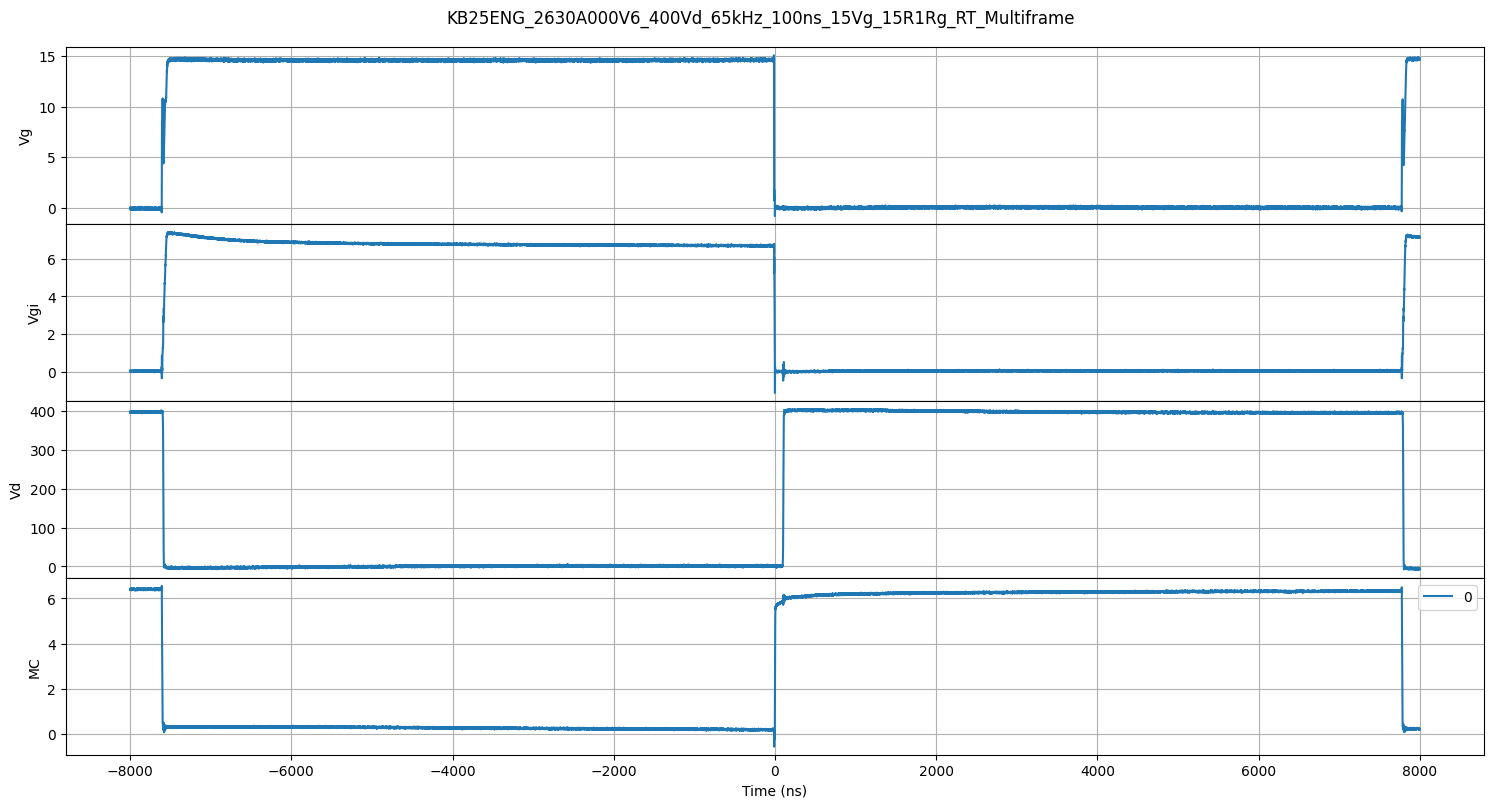

In [9]:
fig, axs = plt.subplots(num, 1, sharex=True, figsize=(15, num*2))
fig.suptitle(tss_file[:-4])
fig.tight_layout()
fig.subplots_adjust(hspace=0)
time1 = tss.waveforms[list(channel_labels.keys())[0]].time_for_frame()*1e9
# print(tss.waveforms[list(channel_labels.keys())[0]].frame_count)

for i in [0]:
    index = 0
    for channel in channel_labels.keys():
        values = tss.waveforms[channel].values_for_frame(i)
        if channel == 'ch2':
            print('channel')
            vgi_edges = WFM_edge(values, time1, rising_edge_number=2, falling_edge_number=1, peak_width=1, peak_distance=10, sigma=10)
            time_vgi_fall = vgi_edges.get_edge(1, "falling", 50)['time']
            print(time_vgi_fall)
        axs[index].plot(time1, values, label=i)
        axs[index].set_ylabel(channel_labels[channel])
        axs[index].grid(True)
        index += 1

plt.legend()
plt.xlabel('Time (ns)')
#plt.xlim([-22e3, 3e3])
plt.legend(loc='best')
plt.show()